Dataset shape: (569, 30)
Number of features: 30

Mean of standardized features:
[-3.16286735e-15 -6.53060890e-15 -7.07889127e-16 -8.79983452e-16
  6.13217737e-15 -1.12036918e-15 -4.42138027e-16  9.73249991e-16
 -1.97167024e-15 -1.45363120e-15 -9.07641468e-16 -8.85349205e-16
  1.77367396e-15 -8.29155139e-16 -7.54180940e-16 -3.92187747e-16
  7.91789988e-16 -2.73946068e-16 -3.10823423e-16 -3.36676596e-16
 -2.33322442e-15  1.76367415e-15 -1.19802625e-15  5.04966114e-16
 -5.21317026e-15 -2.17478837e-15  6.85645643e-16 -1.41265636e-16
 -2.28956670e-15  2.57517109e-15]

Standard deviation of standardized features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

PCA-transformed data shape: (569, 30)
Number of principal components: 30

PCA results:
    Principal Component  Explained Variance Ratio  \
0                     1                  0.442720   
1                     2                  0.189712   
2                     3                  0.09

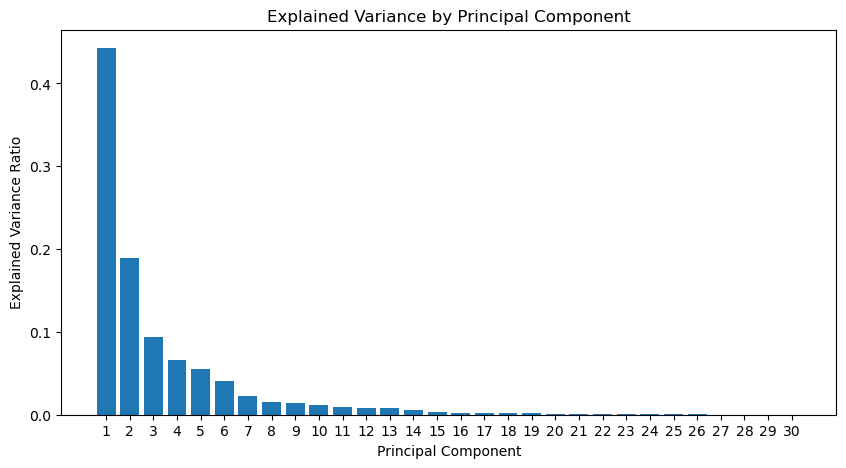

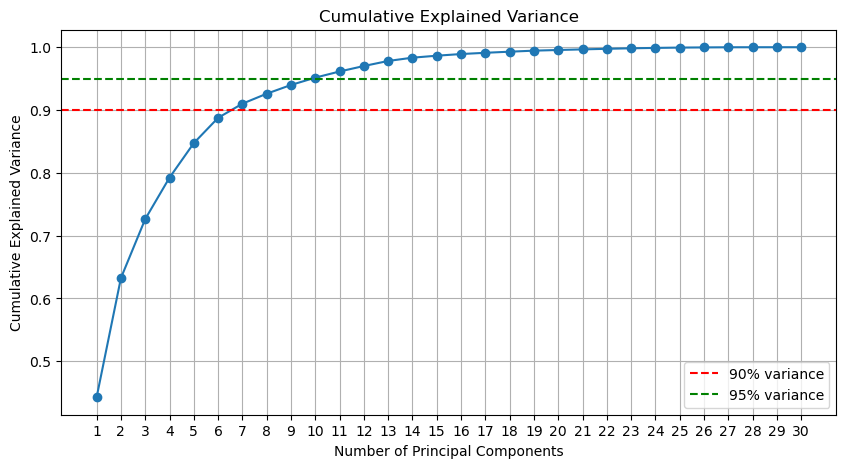


Number of components required to explain at least 95% of the variance: 10
Reduced PCA data shape: (569, 10)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


cancer = load_breast_cancer()

X = cancer.data       
y = cancer.target   

feature_names = cancer.feature_names

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


print("\nMean of standardized features:")
print(X_scaled.mean(axis=0))

print("\nStandard deviation of standardized features:")
print(X_scaled.std(axis=0))


pca = PCA(n_components=None)
X_pca = pca.fit_transform(X_scaled)

print("\nPCA-transformed data shape:", X_pca.shape)
print("Number of principal components:", pca.n_components_)


explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

pca_results = pd.DataFrame({
    "Principal Component": np.arange(1, len(explained_variance_ratio) + 1),
    "Explained Variance Ratio": explained_variance_ratio,
    "Cumulative Explained Variance": cumulative_variance
})

print("\nPCA results:")
print(pca_results)


plt.figure(figsize=(10, 5))
plt.bar(
    range(1, len(explained_variance_ratio) + 1),
    explained_variance_ratio
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by Principal Component")
plt.xticks(range(1, 31))
plt.show()


plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.axhline(y=0.90, color="red", linestyle="--", label="90% variance")
plt.axhline(y=0.95, color="green", linestyle="--", label="95% variance")
plt.xticks(range(1, 31))
plt.legend()
plt.grid()
plt.show()

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(
    f"\nNumber of components required to explain at least "
    f"95% of the variance: {n_components_95}"
)


pca_reduced = PCA(n_components=n_components_95)
X_reduced = pca_reduced.fit_transform(X_scaled)

print("Reduced PCA data shape:", X_reduced.shape)


Variance explained by PC1: 0.4427 (44.27%)
Variance explained by PC2: 0.1897 (18.97%)
Variance explained by PC1 + PC2: 63.24%
Number of components needed for at least 95% variance: 10


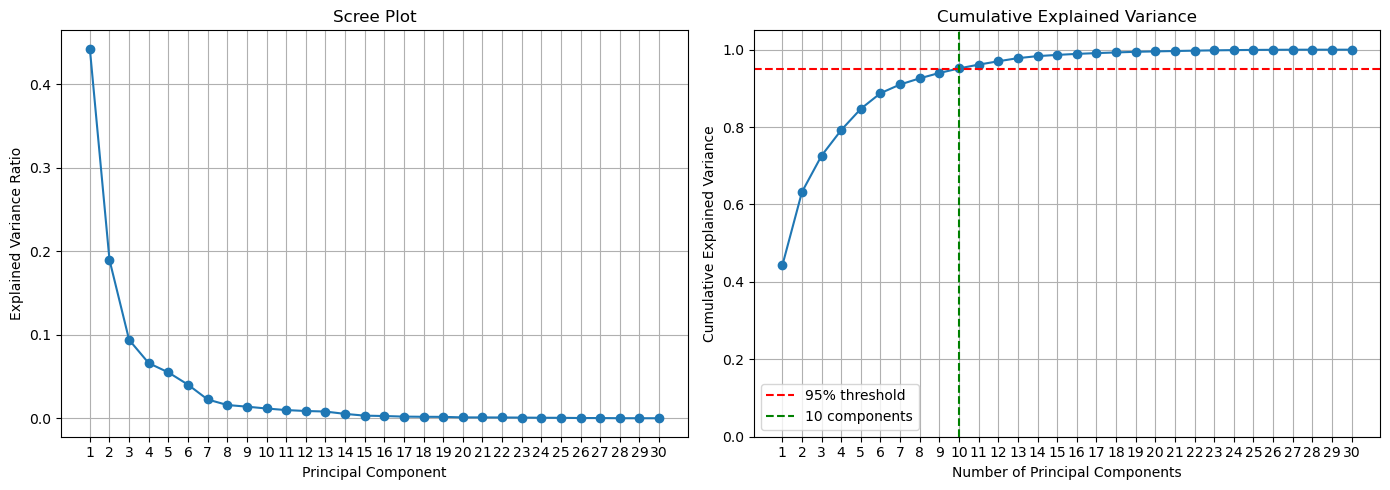

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


data = load_breast_cancer()
X = data.data


X_scaled = StandardScaler().fit_transform(X)


pca = PCA()
X_pca = pca.fit_transform(X_scaled)


explained_variance = pca.explained_variance_ratio_


cumulative_variance = np.cumsum(explained_variance)


print(f"Variance explained by PC1: {explained_variance[0]:.4f} "
      f"({explained_variance[0] * 100:.2f}%)")

print(f"Variance explained by PC2: {explained_variance[1]:.4f} "
      f"({explained_variance[1] * 100:.2f}%)")

print(f"Variance explained by PC1 + PC2: "
      f"{cumulative_variance[1] * 100:.2f}%")


threshold = 0.95
n_components = np.argmax(cumulative_variance >= threshold) + 1

print(f"Number of components needed for at least "
      f"{threshold * 100:.0f}% variance: {n_components}")


components = np.arange(1, len(explained_variance) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    components,
    explained_variance,
    marker="o",
    linestyle="-"
)
axes[0].set_title("Scree Plot")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_xticks(components)
axes[0].grid(True)


axes[1].plot(
    components,
    cumulative_variance,
    marker="o",
    linestyle="-"
)
axes[1].axhline(
    threshold,
    color="red",
    linestyle="--",
    label="95% threshold"
)
axes[1].axvline(
    n_components,
    color="green",
    linestyle="--",
    label=f"{n_components} components"
)
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].set_xticks(components)
axes[1].set_ylim(0, 1.05)
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


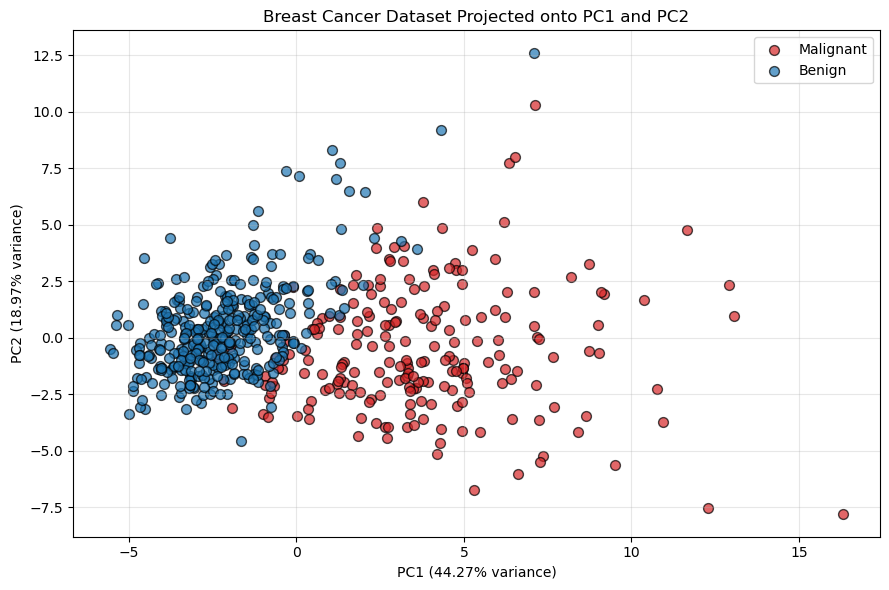

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


data = load_breast_cancer()

X = data.data
y = data.target


X_scaled = StandardScaler().fit_transform(X)


pca = PCA()
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

colors = ["#d62728", "#1f77b4"]
labels = ["Malignant", "Benign"]

for class_value, color, label in zip([0, 1], colors, labels):
    plt.scatter(
        X_pca[y == class_value, 0],
        X_pca[y == class_value, 1],
        color=color,
        label=label,
        alpha=0.7,
        edgecolor="k",
        s=50
    )

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}% variance)"
)
plt.title("Breast Cancer Dataset Projected onto PC1 and PC2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np


pc1_loadings = pd.Series(
    pca.components_[0],
    index=data.feature_names
)


top_pc1 = (
    pc1_loadings.abs()
    .sort_values(ascending=False)
    .head(5)
    .to_frame(name="Absolute Loading")
)


top_pc1["Loading"] = pc1_loadings[top_pc1.index]

print(top_pc1)


                      Absolute Loading   Loading
mean concave points           0.260854  0.260854
mean concavity                0.258400  0.258400
worst concave points          0.250886  0.250886
mean compactness              0.239285  0.239285
worst perimeter               0.236640  0.236640
